In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

### Load the Dataset

In [2]:
df = pd.read_csv("superstore.csv", encoding = 'latin-1')
df_raw = df.copy()          # keep an untouched copy for the before/after comparison

### Inspect the data

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.shape

(9994, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

## Descriptive Statistics BEFORE Preprocessing

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [7]:
df.describe(include = "object").T

C:\Users\User\AppData\Local\Temp\ipykernel_5676\726139619.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include = "object").T


,count,unique,top,freq
Order ID,9994,5009,CA-2017-100111,14
Order Date,9994,1237,9/5/2016,38
Ship Date,9994,1334,12/16/2015,35
Ship Mode,9994,4,Standard Class,5968
Customer ID,9994,793,WB-21850,37
Customer Name,9994,793,William Brown,37
Segment,9994,3,Consumer,5191
Country,9994,1,United States,9994
City,9994,531,New York City,915
State,9994,49,California,2001


**Why:** these numbers are the "before" picture. We compare them with the "after" statistics.
Noted `Sales` and `Profit` have a huge gap between the 75th percentile and the max, which points to outliers.

## Identify & Handle missing values

In [8]:
# -----Check missing values-----
print(df.isnull().sum())


# -----Fill missing numerical values with the median-----
for col in df.select_dtypes(include = "number").columns:
    df[col] = df[col].fillna(df[col].median())


# -----Fill missing text values with the most common value-----
for col in df.select_dtypes(include = "object").columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\n---Missing values handled.---")

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

---Missing values handled.---


C:\Users\User\AppData\Local\Temp\ipykernel_5676\1786776719.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include = "object").columns:


## Remove Duplicates

In [9]:
dup_df = df.drop(columns = "Row ID").duplicated()
print("Duplicates Before:", dup_df.sum())
df = df[~dup_df]
print("Shape after removing duplicates:", df.shape)

Duplicates Before: 1
Shape after removing duplicates: (9993, 21)


**Result:** 1 duplicate was found, so 9,993 rows stayed. The check is still needed in case new data has repeats.

## Detect & Handle Outliers

In [10]:
columns = ["Sales", "Quantity", "Profit"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # count how many values fall outside the limits before capping them
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: lower = {lower:.2f}, upper = {upper:.2f}, values capped = {n_outliers:,} ({n_outliers / len(df):.1%})")

    df[col] = df[col].clip(lower, upper)

print("\nOutliers handled.")

Sales: lower = -271.71, upper = 498.93, values capped = 1,167 (11.7%)
Quantity: lower = -2.50, upper = 9.50, values capped = 170 (1.7%)
Profit: lower = -39.72, upper = 70.81, values capped = 1,881 (18.8%)

Outliers handled.


**Why:** extreme values can distort scaling and models, so values outside the 1.5 × IQR limits are capped rather than deleted, which keeps all rows. Discount was left uncapped because its 0–0.8 values are treated as valid observations.

Profit is heavily tailed, and 18.8% of its values were capped, which compresses the largest gains and losses. This is a trade-off: fewer extreme values, but less information about their original magnitude


## Correct data types
Convert dates to datetime for date calculations. Postal Code is an identifier, so it is stored as text rather than used as a numerical measurement.

In [11]:
df['Order Date'] = pd.to_datetime(df['Order Date'], errors = 'coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors = 'coerce')
df["Postal Code"] = df["Postal Code"].astype("string").str.zfill(5)

print(df.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code              string
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                float64
Discount                float64
Profit                  float64
dtype: object


## Creating New Features

In [12]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Quarter"] = df["Order Date"].dt.quarter
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

df["Profit Status"] = df["Profit"].apply(
    lambda x: "Profit" if x > 0 else "Loss" if x < 0 else "Break-even"
)

df["Profit Margin"] = df_raw["Profit"] / df_raw["Sales"]
df["Unit Price"] = df_raw["Sales"] / df_raw["Quantity"]

df["Order Weekday"] = df["Order Date"].dt.dayofweek


print(df[[
    "Order Year",
    "Order Month",
    "Order Quarter",
    "Shipping Days",
    "Profit Status",
    "Profit Margin", 
    "Unit Price", 
    "Order Weekday"
]].head())

   Order Year  Order Month  Order Quarter  Shipping Days Profit Status  \
0        2016           11              4              3        Profit   
1        2016           11              4              3        Profit   
2        2016            6              2              4        Profit   
3        2015           10              4              7          Loss   
4        2015           10              4              7        Profit   

   Profit Margin  Unit Price  Order Weekday  
0         0.1600    130.9800              1  
1         0.3000    243.9800              1  
2         0.4700      7.3100              6  
3        -0.4000    191.5155              6  
4         0.1125     11.1840              6  


**Why:** each feature adds useful information such as timing, shipping speed and profitability. Profit Margin and Unit Price use the original (uncapped) values from **df_raw**, because ratios of capped values would be wrong. The date features and Profit Status are not affected by capping.

## Encode Categorical Variables

In [13]:
# ------Convert text categories into numerical columns-----
df = pd.get_dummies(df, columns = ["Category", "Segment", "Region", "Ship Mode"], dtype = int)

**Why:** models need numbers, so each category becomes its own 0/1 column.

## Standardize Numerical Features

In [14]:
# -----Use StandardScaler to standardized the selected numerical columns-----
scaler = StandardScaler()
columns = ["Sales", "Quantity", "Discount", "Profit"]
df[columns] = scaler.fit_transform(df[columns])

print(df[columns].head())

      Sales  Quantity  Discount    Profit
0  0.720937 -0.834027 -0.756554  0.876514
1  2.124802 -0.358399 -0.756554  1.856713
2 -0.744362 -0.834027 -0.756554 -0.312014
3  2.124802  0.592857  1.423182 -1.892206
4 -0.698461 -0.834027  0.212218 -0.459723


**Why:** puts features on the same scale so large values like Sales don’t dominate.

**Note:** scaling here is fitted on all rows, so `cleaned_superstore.csv` is meant for analysis. For model training, use the pipeline below, which fits the scaler on the training split only to avoid data leakage.

## Descriptive Statistics AFTER Preprocessing

In [15]:
df[["Sales","Quantity","Discount","Profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,9993.0,-1.528737e-17,1.00005,-0.828343,-0.728603,-0.508222,0.412759,2.124802
Quantity,9993.0,1.203436e-16,1.00005,-1.309655,-0.834027,-0.358399,0.592857,2.733183
Discount,9993.0,7.821445e-17,1.00005,-0.756554,-0.756554,0.212218,0.212218,3.118533
Profit,9993.0,-6.399364e-18,1.00005,-1.892206,-0.486361,-0.250977,0.450868,1.856713


Values are now standardized (mean ≈ 0, std = 1) and extremes are capped, unlike the before table.

## Visualize BoxPlot

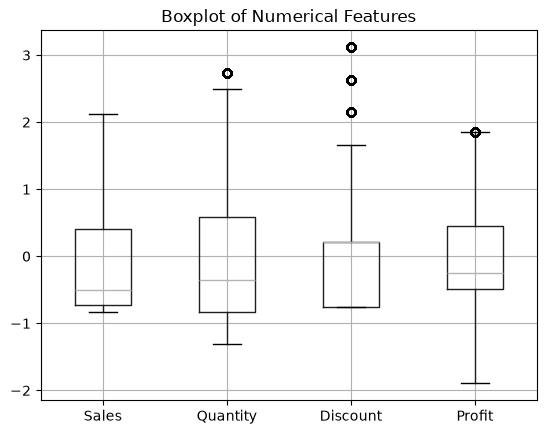

In [16]:
df[["Sales", "Quantity", "Discount", "Profit"]].boxplot()
plt.title("Boxplot of Numerical Features")
plt.show()

# Scikit-learn Preprocessing Pipeline

Reusable pipeline template that automates imputing, encoding and scaling, fitted on training data only to avoid leakage.

In [17]:
data = pd.read_csv("superstore.csv", encoding = "latin-1")

# -----Select a few useful features-----
X = data[["Sales", "Quantity", "Discount", "Profit", "Category", "Region"]]

# -----Separate numerical and categorical columns-----
num_cols = ["Sales", "Quantity", "Discount", "Profit"]
cat_cols = ["Category", "Region"]

# -----Numerical preprocessing-----
num_pipe = Pipeline([
    ("fill", SimpleImputer(strategy = "median")),
    ("scale", StandardScaler())
])

# -----Categorical preprocessing-----
cat_pipe = Pipeline([
    ("fill", SimpleImputer(strategy = "most_frequent")),
    ("encode", OneHotEncoder(handle_unknown = "ignore"))
])

# -----Combine both pipelines-----
preprocessor = ColumnTransformer([
    ("numbers", num_pipe, num_cols),
    ("categories", cat_pipe, cat_cols)
])

# -----Split data before fitting the preprocessing pipeline-----
X_train, X_test = train_test_split(
    X, test_size = 0.2, random_state = 42
)

# -----Fit on training data and transform both sets-----
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (7995, 11)
Testing data: (1999, 11)


The data is split 80/20 first and the pipeline is fitted on the training set only, which helps prevent data leakage. The result is 7,995 training rows and 1,999 test rows with 11 processed features: 4 numeric features, 3 one-hot Category columns and 4 one-hot Region columns.

This pipeline is a separate modelling example, not the same transformation as the cleaned CSV export. It uses only Category and Region as categorical inputs, while the full workflow encodes Category, Segment, Region and Ship Mode, so the two outputs are not expected to have the same number of columns. It is also fitted on the raw file (9,994 rows, before duplicate removal), so its row counts differ by one from the cleaned CSV (9,993 rows).


### Save the Cleaned dataset

In [18]:
df = df.drop(columns = ["Row ID", "Country"])
df.to_csv("cleaned_superstore.csv", index = False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
